# Examen Final

Carrera: Ingeniería Civil Industrial

Asignatura: Machine Learning - EINGT1029-01

Profesor: Franco Mansilla  

Alumno: Melanie Olguin

Fecha de Entrega: 18-10-2026



In [28]:
!pip -q install scikit-learn pandas numpy matplotlib

In [29]:
#1. Generación de datos, EDA y outliers

import os, warnings, json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from sklearn.inspection import permutation_importance
from scipy.stats import randint
import joblib
SEED=42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
Path('resultados').mkdir(exist_ok=True)

Archivo: /content/train.csv | Dimensiones: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Duplicados completos: 0


,Nulos
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81


,Precio de venta
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


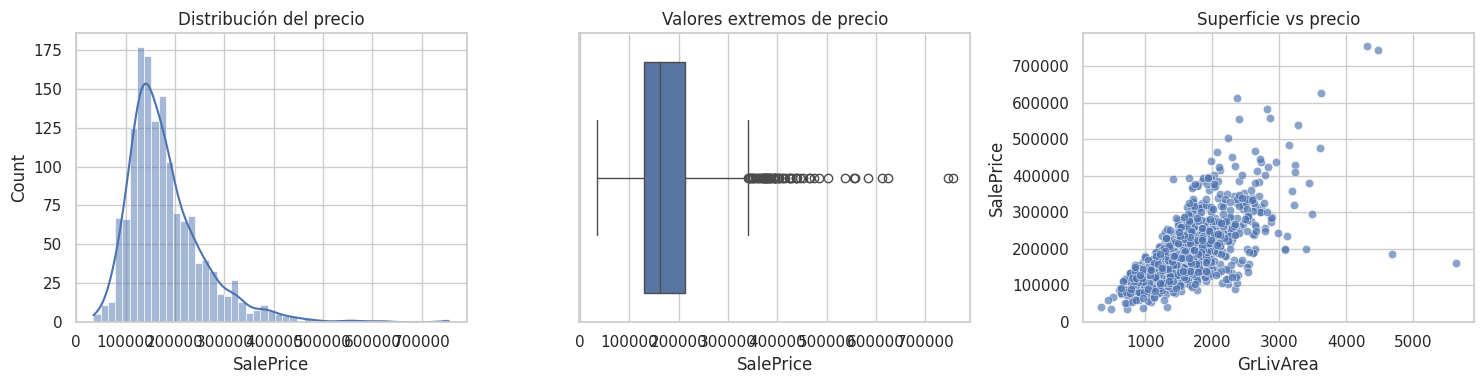

In [30]:
#2. EDA, limpieza, valores faltantes y outliers

ruta = '/content/train.csv'
if not os.path.isfile(ruta):
    raise FileNotFoundError('No se encontró /content/train.csv. Verifica el nombre en el panel Archivos de Colab.')
df = pd.read_csv(ruta)
assert 'SalePrice' in df.columns, 'La base debe contener SalePrice.'
print('Archivo:', ruta, '| Dimensiones:', df.shape)
display(df.head())
print('Duplicados completos:', df.duplicated().sum())
display(df.isna().sum().sort_values(ascending=False).head(18).to_frame('Nulos'))
display(df['SalePrice'].describe().to_frame('Precio de venta'))
fig, axes = plt.subplots(1,3,figsize=(15,4))
sns.histplot(df.SalePrice, kde=True, ax=axes[0]); axes[0].set_title('Distribución del precio')
sns.boxplot(x=df.SalePrice, ax=axes[1]); axes[1].set_title('Valores extremos de precio')
sns.scatterplot(data=df,x='GrLivArea',y='SalePrice',ax=axes[2],alpha=.65);axes[2].set_title('Superficie vs precio')
plt.tight_layout();plt.savefig('resultados/eda.png',dpi=150);plt.show()

In [31]:
# Separación ANTES de imputar o escalar

X = df.drop(columns=['SalePrice','Id'],errors='ignore').copy()
y = df['SalePrice'].copy()
# MSSubClass es un código de categoría, no una magnitud continua.
if 'MSSubClass' in X: X['MSSubClass'] = X['MSSubClass'].astype('str')
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.2,random_state=SEED)
num_cols=X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols=[c for c in X_train.columns if c not in num_cols]
def preprocesador(escalar=True, codificar=True):
    numerico=Pipeline([('imputar',SimpleImputer(strategy='median',add_indicator=False)),
                       ('escalar',StandardScaler() if escalar else 'passthrough')])
    categorico=Pipeline([('imputar',SimpleImputer(strategy='constant',fill_value='NoInformado')),
                         ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    pasos=[('numerico',numerico,num_cols)]
    if codificar: pasos.append(('categorico',categorico,cat_cols))
    return ColumnTransformer(pasos,remainder='drop',sparse_threshold=0)
def medir_reg(yreal,ypred):
    return {'MAE':mean_absolute_error(yreal,ypred),
            'RMSE':np.sqrt(mean_squared_error(yreal,ypred)),
            'R2':r2_score(yreal,ypred)}
print('Train:',X_train.shape,'Test:',X_test.shape,
      '| Numéricas:',len(num_cols),'Categóricas:',len(cat_cols))

Train: (1168, 79) Test: (292, 79) | Numéricas: 35 Categóricas: 44


LotFrontage: media=70.34, mediana=70.00, nulos=217


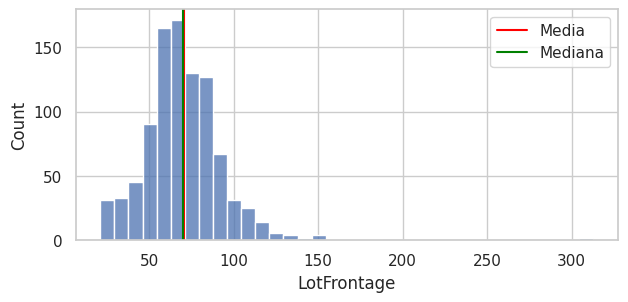

In [32]:
# Experimento controlado

col='LotFrontage'
observados=X_train[col].dropna()
print(f'{col}: media={observados.mean():.2f}, mediana={observados.median():.2f}, nulos={X_train[col].isna().sum()}')
fig,ax=plt.subplots(figsize=(7,3))
sns.histplot(observados,ax=ax,bins=35)
ax.axvline(observados.mean(),color='red',label='Media')
ax.axvline(observados.median(),color='green',label='Mediana')
ax.legend();plt.show()


In [33]:
#3. Lasso, Ridge y Elastic Net


from sklearn.model_selection import GridSearchCV
cv=KFold(n_splits=3,shuffle=True,random_state=SEED)
parametros={'Lasso':(Lasso(max_iter=25000),{'modelo__alpha':[10,100,500,1000]}),
            'Ridge':(Ridge(),{'modelo__alpha':[1,10,100,500]}),
            'ElasticNet':(ElasticNet(max_iter=25000),{'modelo__alpha':[10,100,500],
                                                     'modelo__l1_ratio':[.2,.5,.8]})}
resultados_reg=[]
modelos_reg={}
for nombre,(estimador,grid) in parametros.items():
    pipe=Pipeline([('pre',preprocesador()),('modelo',estimador)])
    busq=GridSearchCV(pipe,grid,scoring='neg_root_mean_squared_error',cv=cv,n_jobs=-1)
    busq.fit(X_train,y_train)
    pred=busq.predict(X_test)
    resultados_reg.append({'Modelo':nombre,**medir_reg(y_test,pred),
                           'Mejor configuración':str(busq.best_params_),
                           'Coeficientes no cero':int(np.sum(np.abs(busq.best_estimator_.named_steps['modelo'].coef_)>1e-7))})
    modelos_reg[nombre]=busq.best_estimator_
tabla_reg=pd.DataFrame(resultados_reg).sort_values('RMSE')
display(tabla_reg)
tabla_reg.to_csv('resultados/regresiones_penalizadas.csv',index=False)

,Modelo,MAE,RMSE,R2,Mejor configuración,Coeficientes no cero
0,Lasso,17123.070719,28355.674178,0.895175,{'modelo__alpha': 100},114
1,Ridge,19228.312679,30612.964787,0.877821,{'modelo__alpha': 10},315
2,ElasticNet,23535.494282,43043.994912,0.758448,"{'modelo__alpha': 10, 'modelo__l1_ratio': 0.8}",307


In [34]:
#4. Escalamiento y One-Hot: red neuronal y DBSCAN

# Se compara MLP con y sin escalamiento. One-Hot se mantiene en ambos.


resultados_mlp=[]
for escala in [False,True]:
    pipe=Pipeline([('pre',preprocesador(escalar=escala)),
                   ('modelo',MLPRegressor(hidden_layer_sizes=(32,),max_iter=350,
                                          early_stopping=True,random_state=SEED))])
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        pipe.fit(X_train,y_train)
    resultados_mlp.append({'Escalado':escala,**medir_reg(y_test,pipe.predict(X_test))})
display(pd.DataFrame(resultados_mlp))
print('Advertencia: MLP es sensible a inicialización y convergencia')

,Escalado,MAE,RMSE,R2
0,False,32451.843688,51760.717820,0.65071
1,True,170658.617058,190977.094458,-3.75498


Advertencia: MLP es sensible a inicialización y convergencia


In [35]:
#5. PCA antes de Random Forest y K-Means


comparacion_rf=[]
rf_modelos={}
for usar_pca in [False,True]:
    pasos=[('pre',preprocesador(escalar=True))]
    if usar_pca: pasos.append(('pca',PCA(n_components=.95,random_state=SEED)))
    pasos.append(('modelo',RandomForestRegressor(n_estimators=120,min_samples_leaf=2,
                                                random_state=SEED,n_jobs=-1)))
    pipe=Pipeline(pasos).fit(X_train,y_train)
    comparacion_rf.append({'PCA':usar_pca,**medir_reg(y_test,pipe.predict(X_test)),
                            'Componentes':pipe.named_steps['pca'].n_components_ if usar_pca else 'Originales'})
    rf_modelos[usar_pca]=pipe
display(pd.DataFrame(comparacion_rf))
pd.DataFrame(comparacion_rf).to_csv('resultados/rf_pca.csv',index=False)

,PCA,MAE,RMSE,R2,Componentes
0,False,17728.010171,29305.752956,0.888033,Originales
1,True,18320.606087,31378.655921,0.871633,82


In [36]:
# Segmentación de viviendas SIN usar SalePrice como característica.


X_cluster=X.sample(n=min(700,len(X)),random_state=SEED)
base_cl=preprocesador(escalar=True).fit_transform(X_cluster)
pca=PCA(n_components=.90,random_state=SEED)
datos_pca=pca.fit_transform(base_cl)
print('Dimensión original:',base_cl.shape[1],'| PCA 90%:',datos_pca.shape[1])
def metricas_cluster(datos,etiquetas):
    # En DBSCAN -1 significa ruido; excluirlo para medir cohesión de clusters.
    mask=etiquetas!=-1
    etiquetas_validas=etiquetas[mask]
    if len(set(etiquetas_validas))<2 or mask.sum()<3:
        return {'Silhouette':np.nan,'Calinski-Harabasz':np.nan,'Davies-Bouldin':np.nan,
                'Clusters':len(set(etiquetas_validas)),'Ruido':int((~mask).sum())}
    return {'Silhouette':silhouette_score(datos[mask],etiquetas_validas,
                                         sample_size=min(450,mask.sum()),random_state=SEED),
            'Calinski-Harabasz':calinski_harabasz_score(datos[mask],etiquetas_validas),
            'Davies-Bouldin':davies_bouldin_score(datos[mask],etiquetas_validas),
            'Clusters':len(set(etiquetas_validas)),'Ruido':int((~mask).sum())}
res_cl=[]
clusters_guardados={}
for nombre,datos in [('Sin PCA',base_cl),('Con PCA',datos_pca)]:
    for k in [3,4,5]:
        et=KMeans(n_clusters=k,n_init=10,random_state=SEED).fit_predict(datos)
        res_cl.append({'Método':'K-Means','Representación':nombre,'Parámetro':f'k={k}',**metricas_cluster(datos,et)})
        clusters_guardados[(nombre,k)]=et
tabla_cluster=pd.DataFrame(res_cl)
display(tabla_cluster.sort_values('Silhouette',ascending=False))
tabla_cluster.to_csv('resultados/kmeans_pca.csv',index=False)

Dimensión original: 301 | PCA 90%: 53


,Método,Representación,Parámetro,Silhouette,Calinski-Harabasz,Davies-Bouldin,Clusters,Ruido
3,K-Means,Con PCA,k=3,0.126617,83.105694,2.474879,3,0
4,K-Means,Con PCA,k=4,0.092259,66.723823,2.985219,4,0
5,K-Means,Con PCA,k=5,0.086767,56.013514,2.926346,5,0
2,K-Means,Sin PCA,k=5,0.083319,50.664238,2.890197,5,0
1,K-Means,Sin PCA,k=4,0.078301,58.552482,3.128486,4,0
0,K-Means,Sin PCA,k=3,0.074522,69.178047,2.906016,3,0


In [37]:
# DBSCAN: comparar distancia sin escalar y escalada, y diferentes eps.

num_cl=SimpleImputer(strategy='median').fit_transform(X_cluster[num_cols])
num_cl_escalado=StandardScaler().fit_transform(num_cl)
db_rows=[]
for representacion,datos,eps_values in [('Numéricas sin escalar',num_cl,[100,500,1000]),
                                        ('Numéricas escaladas',num_cl_escalado,[2,4,6]),
                                        ('One-Hot + escaladas',base_cl,[4,7,10])]:
    for eps in eps_values:
        et=DBSCAN(eps=eps,min_samples=6).fit_predict(datos)
        db_rows.append({'Representación':representacion,'eps':eps,**metricas_cluster(datos,et)})
tabla_db=pd.DataFrame(db_rows)
display(tabla_db)
tabla_db.to_csv('resultados/dbscan_escalamiento.csv',index=False)


,Representación,eps,Silhouette,Calinski-Harabasz,Davies-Bouldin,Clusters,Ruido
0,Numéricas sin escalar,100,NaN,NaN,NaN,0,700
1,Numéricas sin escalar,500,0.446425,194.849267,0.717069,13,553
2,Numéricas sin escalar,1000,NaN,NaN,NaN,1,103
3,Numéricas escaladas,2,0.316121,8.502582,1.115046,2,686
4,Numéricas escaladas,4,NaN,NaN,NaN,1,234
5,Numéricas escaladas,6,NaN,NaN,NaN,1,42
6,One-Hot + escaladas,4,0.252850,19.368749,1.441000,2,638
7,One-Hot + escaladas,7,0.136340,9.254354,1.567288,2,86
8,One-Hot + escaladas,10,NaN,NaN,NaN,1,11


In [38]:
#6 y 7. Benchmarking supervisado/no supervisado y métricas

# Baseline, modelos lineales y Random Forest evaluados sobre el MISMO conjunto test

from sklearn.dummy import DummyRegressor
candidatos={
    'Baseline (mediana)':Pipeline([('pre',preprocesador()),('modelo',DummyRegressor(strategy='median'))]),
    'Regresión lineal':Pipeline([('pre',preprocesador()),('modelo',LinearRegression())]),
    'Ridge':modelos_reg['Ridge'],
    'Elastic Net':modelos_reg['ElasticNet'],
    'Random Forest':rf_modelos[False]
}
res_benchmark=[]
for nombre,modelo in candidatos.items():
    if nombre in ['Baseline (mediana)','Regresión lineal']: modelo.fit(X_train,y_train)
    res_benchmark.append({'Modelo':nombre,**medir_reg(y_test,modelo.predict(X_test))})
benchmark=pd.DataFrame(res_benchmark).sort_values('RMSE')
display(benchmark)
benchmark.to_csv('resultados/benchmark.csv',index=False)
print('Métrica principal para SalePrice: RMSE o MAE; AUC y F1 no aplican a regresión continua.')
print('Para clustering: Silhouette/Calinski-Harabasz y revisión de estabilidad y sentido comercial.')

,Modelo,MAE,RMSE,R2
4,Random Forest,17728.010171,29305.752956,0.888033
2,Ridge,19228.312679,30612.964787,0.877821
3,Elastic Net,23535.494282,43043.994912,0.758448
1,Regresión lineal,21515.400287,70490.558133,0.352189
0,Baseline (mediana),59568.250000,88667.167506,-0.024972


Métrica principal para SalePrice: RMSE o MAE; AUC y F1 no aplican a regresión continua.
Para clustering: Silhouette/Calinski-Harabasz y revisión de estabilidad y sentido comercial.


,Viviendas,Precio_mediano,Superficie_mediana,Calidad_mediana,Año_mediano
Segmento,,,,,
0,129,232000.0,1571.0,7.0,2005.0
1,173,215000.0,1933.0,7.0,1999.0
2,170,118200.0,1177.0,5.0,1935.5
3,201,144000.0,1152.0,5.0,1966.0
4,27,136500.0,1728.0,5.0,1967.0


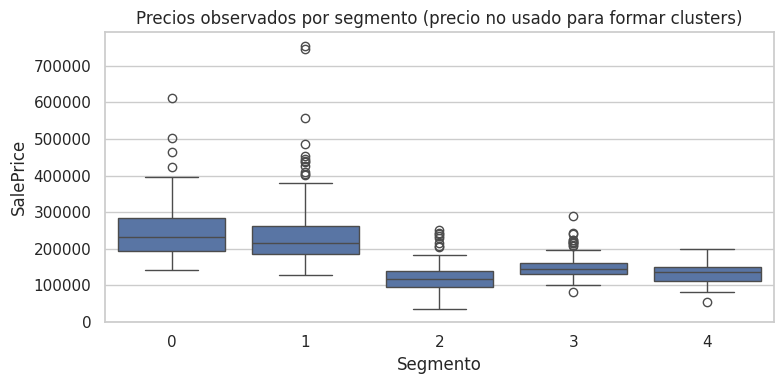

In [39]:
# Integración de negocio: caracterizar segmentos por precio

mejor_k=tabla_cluster.query("Representación == 'Sin PCA'").sort_values('Silhouette',ascending=False).iloc[0]['Parámetro']
k=int(mejor_k.split('=')[1])
et=clusters_guardados[('Sin PCA',k)]
segmentos=df.loc[X_cluster.index,['SalePrice','GrLivArea','OverallQual','YearBuilt']].copy()
segmentos['Segmento']=et
perfil=segmentos.groupby('Segmento').agg(Viviendas=('SalePrice','size'),
                                         Precio_mediano=('SalePrice','median'),
                                         Superficie_mediana=('GrLivArea','median'),
                                         Calidad_mediana=('OverallQual','median'),
                                         Año_mediano=('YearBuilt','median'))
display(perfil)
perfil.to_csv('resultados/perfil_segmentos.csv')
fig,ax=plt.subplots(figsize=(8,4))
sns.boxplot(data=segmentos,x='Segmento',y='SalePrice',ax=ax)
ax.set_title('Precios observados por segmento (precio no usado para formar clusters)')
plt.tight_layout();plt.savefig('resultados/segmentos_precio.png',dpi=150);plt.show()

In [40]:
#8. Optimización y control del sobreajuste

pipe_rf=Pipeline([('pre',preprocesador(escalar=False)),
                  ('modelo',RandomForestRegressor(random_state=SEED,n_jobs=1))])
distribuciones={'modelo__n_estimators':[80,120,180],
                'modelo__max_depth':[None,8,15,25],
                'modelo__min_samples_leaf':[1,2,4],
                'modelo__max_features':[.5,.8,1.]}
busqueda=RandomizedSearchCV(pipe_rf,distribuciones,n_iter=8,cv=3,
                            scoring='neg_root_mean_squared_error',
                            n_jobs=-1,random_state=SEED,refit=True)
inicio=time.time();busqueda.fit(X_train,y_train)
print('Tiempo (s):',round(time.time()-inicio,1))
print('Parámetros:',busqueda.best_params_)
display(pd.DataFrame([{'Modelo':'RF base',**medir_reg(y_test,rf_modelos[False].predict(X_test))},
                      {'Modelo':'RF optimizado',**medir_reg(y_test,busqueda.predict(X_test))}]))

Tiempo (s): 48.1
Parámetros: {'modelo__n_estimators': 120, 'modelo__min_samples_leaf': 2, 'modelo__max_features': 0.5, 'modelo__max_depth': None}


,Modelo,MAE,RMSE,R2
0,RF base,17728.010171,29305.752956,0.888033
1,RF optimizado,16948.016546,28587.473580,0.893454


In [41]:
#9. Reproducibilidad y GitHub

import sklearn, sys
joblib.dump(busqueda.best_estimator_,'resultados/modelo_rf_optimizado.joblib')
with open('resultados/versiones.txt','w') as f:
    f.write(f'python={sys.version.split()[0]}\nscikit-learn={sklearn.__version__}\n'
            f'pandas={pd.__version__}\nnumpy={np.__version__}\nseed={SEED}\n')
readme='''# Predicción y segmentación de viviendas
1. Abrir el notebook en Google Colab.
2. Subir train(2).csv cuando se solicite.
3. Ejecutar las celdas en orden.
4. Revisar resultados/ (gráficos, métricas y modelo).
No subir información sensible. Los resultados dependen de versiones y del CSV usado.
'''
Path('resultados/README.md').write_text(readme,encoding='utf-8')
print('Archivos generados:',[p.name for p in Path('resultados').iterdir()])

Archivos generados: ['perfil_segmentos.csv', 'modelo_rf_optimizado.joblib', 'eda.png', 'rf_pca.csv', 'versiones.txt', 'README.md', 'benchmark.csv', 'kmeans_pca.csv', 'real_vs_predicho.png', 'dbscan_escalamiento.csv', 'regresiones_penalizadas.csv', 'segmentos_precio.png']


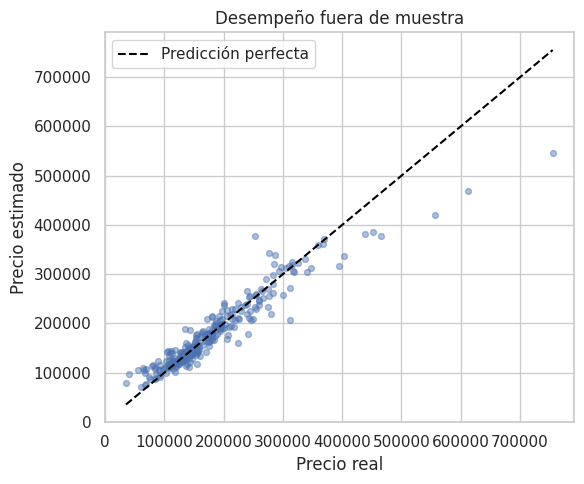

RMSE test: 28587.47


In [42]:
#10 y 11. Storytelling, interpretación y ciclo continuo

# Gráfico de comunicación: valor real vs predicción del modelo seleccionado.

modelo_final=busqueda.best_estimator_
pred_final=modelo_final.predict(X_test)
fig,ax=plt.subplots(figsize=(6,5))
ax.scatter(y_test,pred_final,alpha=.45,s=18)
limites=[min(y_test.min(),pred_final.min()),max(y_test.max(),pred_final.max())]
ax.plot(limites,limites,'--',color='black',label='Predicción perfecta')
ax.set(xlabel='Precio real',ylabel='Precio estimado',title='Desempeño fuera de muestra')
ax.legend();plt.tight_layout();plt.savefig('resultados/real_vs_predicho.png',dpi=150);plt.show()
print('RMSE test:',round(np.sqrt(mean_squared_error(y_test,pred_final)),2))
